# Allstate Claims Severity
## 01 — Data Understanding

### Objective
The goal of this project is to predict insurance claim severity
using historical claim data.

This is a supervised regression problem where `loss` represents
the target variable.

### In This Notebook
- Load and inspect the dataset.
- Explore feature types and dataset structure.
- Identify missing values and duplicate records.
- Examine the distribution of the target variable.
- Summarize initial observations and findings.

In [2]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python path:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Python path: /Users/ebrietas/Allstate_Claims_Severity/.venv/bin/python
Pandas: 3.1.0
NumPy: 2.5.4
Scikit-learn: 1.9.1


## 1. Data Loading

Load the training and test datasets using Pandas.

The training dataset includes the target variable (`loss`),
while the test dataset is used for generating predictions.

We will first verify their dimensions and structure.

In [3]:
from pathlib import Path

import pandas as pd

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data" / "raw"

train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (188318, 132)
Test shape: (125546, 131)


## 2. Initial Data Inspection

Before preprocessing or modeling, we need to understand the structure
and characteristics of the datasets.

In this section, we will:
- Preview the first few records.
- Examine column names and data types.
- Identify the target variable and feature groups.
- Compare the training and test dataset structures.

In [4]:
display(train.head())
display(test.head())

,id,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,...,cont6,cont7,cont8,cont9,cont10,cont11,cont12,cont13,cont14,loss
0,1,A,B,A,B,A,A,A,A,B,...,0.718367,0.335060,0.30260,0.67135,0.83510,0.569745,0.594646,0.822493,0.714843,2213.18
1,2,A,B,A,A,A,A,A,A,B,...,0.438917,0.436585,0.60087,0.35127,0.43919,0.338312,0.366307,0.611431,0.304496,1283.60
2,5,A,B,A,A,B,A,A,A,B,...,0.289648,0.315545,0.27320,0.26076,0.32446,0.381398,0.373424,0.195709,0.774425,3005.09
3,10,B,B,A,B,A,A,A,A,B,...,0.440945,0.391128,0.31796,0.32128,0.44467,0.327915,0.321570,0.605077,0.602642,939.85
4,11,A,B,A,B,A,A,A,A,B,...,0.178193,0.247408,0.24564,0.22089,0.21230,0.204687,0.202213,0.246011,0.432606,2763.85


,id,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,...,cont5,cont6,cont7,cont8,cont9,cont10,cont11,cont12,cont13,cont14
0,4,A,B,A,A,A,A,A,A,B,...,0.281143,0.466591,0.317681,0.61229,0.34365,0.38016,0.377724,0.369858,0.704052,0.392562
1,6,A,B,A,B,A,A,A,A,B,...,0.836443,0.482425,0.443760,0.71330,0.51890,0.60401,0.689039,0.675759,0.453468,0.208045
2,9,A,B,A,B,B,A,B,A,B,...,0.718531,0.212308,0.325779,0.29758,0.34365,0.30529,0.245410,0.241676,0.258586,0.297232
3,12,A,A,A,A,B,A,A,A,A,...,0.397069,0.369930,0.342355,0.40028,0.33237,0.31480,0.348867,0.341872,0.592264,0.555955
4,15,B,A,A,A,A,B,A,A,A,...,0.302678,0.398862,0.391833,0.23688,0.43731,0.50556,0.359572,0.352251,0.301535,0.825823


In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 188318 entries, 0 to 188317
Columns: 132 entries, id to loss
dtypes: float64(15), int64(1), str(116)
memory usage: 189.7 MB


## 3. Data Quality Assessment

Before exploring feature distributions, we assess the basic
quality and integrity of the datasets.

This section focuses on:
- Detecting missing values in training and test data.
- Identifying duplicate records.
- Verifying the uniqueness of record identifiers.

The findings will help determine whether data cleaning is required.

In [6]:
print("Train missing values:", train.isna().sum().sum())
print("Test missing values:", test.isna().sum().sum())

print("Train duplicates:", train.duplicated().sum())
print("Test duplicates:", test.duplicated().sum())

print("Train unique IDs:", train["id"].nunique())
print("Test unique IDs:", test["id"].nunique())

Train missing values: 0
Test missing values: 0
Train duplicates: 0
Test duplicates: 0
Train unique IDs: 188318
Test unique IDs: 125546


### Data Quality Findings

The initial data quality assessment shows that:

- Neither dataset contains missing values.
- No fully duplicated records were detected.
- No missing-value imputation or duplicate removal is required at this stage.

Record identifier uniqueness is checked separately to validate data integrity.

In [7]:
train_duplicates = train.drop(columns=["id"]).duplicated().sum()
test_duplicates = test.drop(columns=["id"]).duplicated().sum()

print("Train duplicates (excluding ID):", train_duplicates)
print("Test duplicates (excluding ID):", test_duplicates)

Train duplicates (excluding ID): 0
Test duplicates (excluding ID): 0


In [ ]:
print("Train IDs unique:", train["id"].is_unique)
print("Test IDs unique:", test["id"].is_unique)

Train IDs unique: True
Test IDs unique: True


### Data Quality Findings

The initial data quality checks reveal the following:

- **Missing Values:** Neither dataset contains missing values.
- **Duplicate Records:** No fully duplicated records were detected, even after excluding the `id` column.
- **ID Uniqueness:** All record identifiers are unique within each dataset.
- **Data Cleaning:** No missing-value imputation or duplicate removal is required at this stage.

These results indicate that the datasets have good initial data quality.
Further analysis is needed to investigate outliers, feature distributions,
and potential inconsistencies.

## 4. Target Variable Analysis

The target variable `loss` represents the insurance claim amount
that our model aims to predict.

We will examine its statistical properties and distribution to
understand typical claim amounts, variability, and potential outliers.

These findings will guide our preprocessing and modeling decisions.

In [12]:
train["loss"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    188318.000000
mean       3037.337686
std        2904.086186
min           0.670000
25%        1204.460000
50%        2115.570000
75%        3864.045000
90%        6401.743000
95%        8508.536500
99%       13981.203000
max      121012.250000
Name: loss, dtype: float64

### Initial Target Insights

The descriptive statistics suggest a positively skewed target distribution.

- The mean (3,037.34) exceeds the median (2,115.57), suggesting that large claims influence the average.
- The 99th percentile is approximately 13,981, while the maximum reaches 121,012.
- The large upper-tail values indicate potential extreme observations that require further investigation.

We will examine the distribution visually before making any preprocessing decisions.

### 4.1 Loss Distribution

We visualize the distribution of claim losses using a histogram.

This helps identify the most frequent loss ranges, assess distribution
asymmetry, and investigate the influence of unusually large claims.

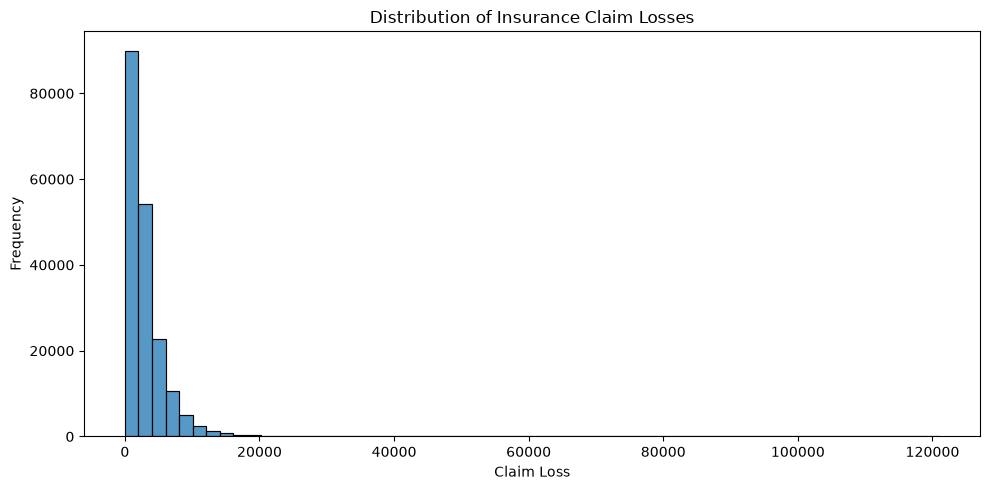

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=train,
    x="loss",
    bins=60
)

plt.title("Distribution of Insurance Claim Losses")
plt.xlabel("Claim Loss")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### 4.2 Zoomed Loss Distribution

The full histogram is heavily compressed due to extreme claim values.

To better understand the distribution of typical claims, we visualize
loss values up to the 99th percentile.

This visualization excludes extreme values from the plot only;
the original dataset remains unchanged.

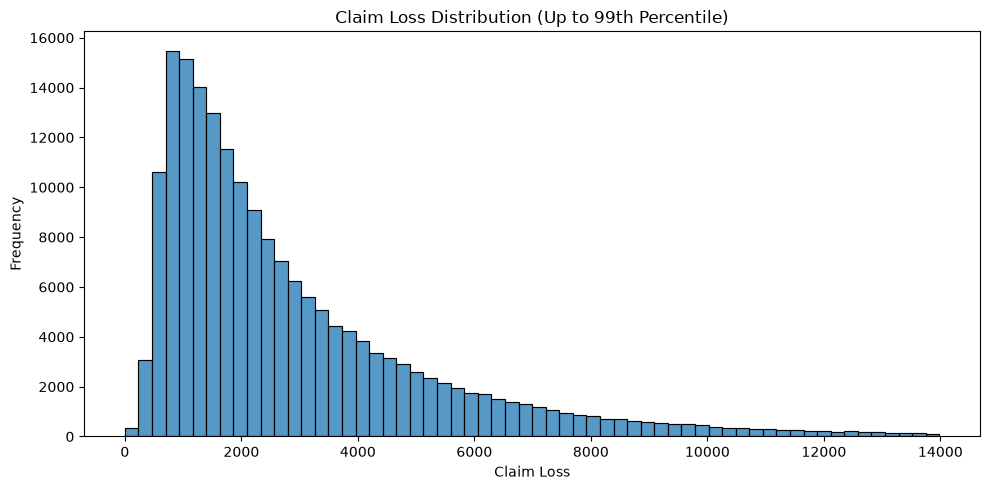

In [15]:
p99 = train["loss"].quantile(0.99)

loss_zoomed = train.loc[train["loss"] <= p99, "loss"]

plt.figure(figsize=(10, 5))

sns.histplot(
    loss_zoomed,
    bins=60
)

plt.title("Claim Loss Distribution (Up to 99th Percentile)")
plt.xlabel("Claim Loss")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [16]:
print("Loss skewness:", train["loss"].skew())

Loss skewness: 3.794958377537858


### 4.3 Boxplot and Outlier Detection

We use a boxplot and the Interquartile Range (IQR) method to
investigate unusually large insurance claims.

The analysis aims to:
- Examine the spread of the middle 50% of claim losses.
- Identify observations outside the standard IQR boundaries.
- Assess whether extreme values require further investigation.

Statistical outliers will not be automatically removed.

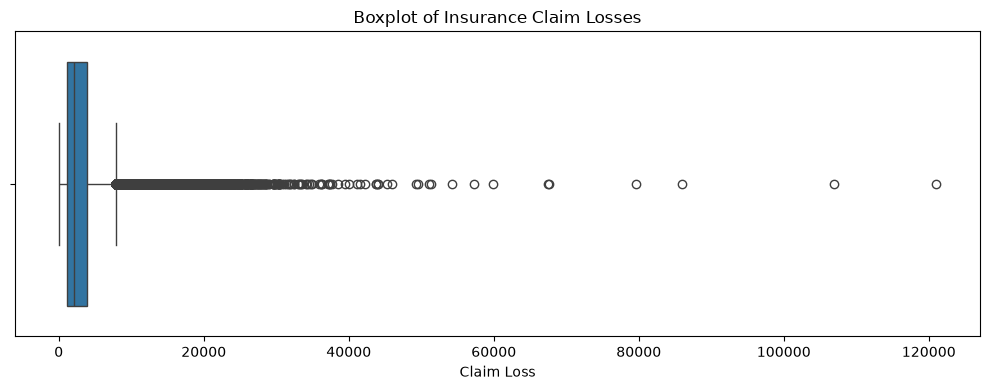

In [32]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=train["loss"])

plt.title("Boxplot of Insurance Claim Losses")
plt.xlabel("Claim Loss")

plt.tight_layout()
plt.show()

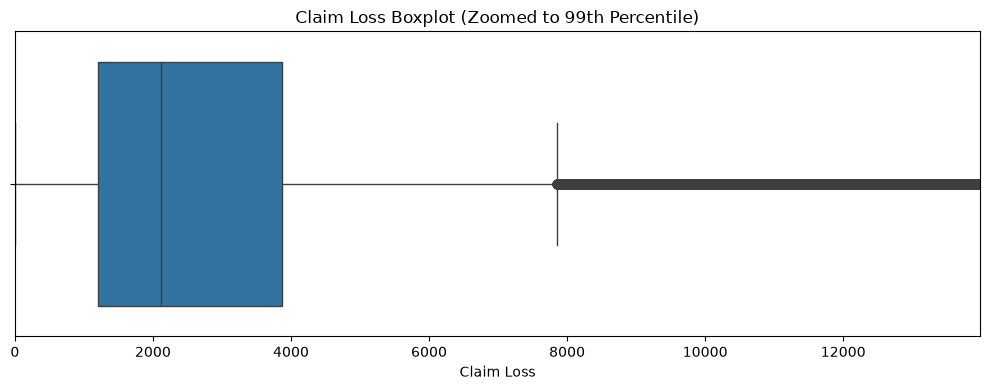

In [33]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=train["loss"])

plt.xlim(0, train["loss"].quantile(0.99))

plt.title("Claim Loss Boxplot (Zoomed to 99th Percentile)")
plt.xlabel("Claim Loss")

plt.tight_layout()
plt.show()

In [34]:
q1 = train["loss"].quantile(0.25)
q3 = train["loss"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Lower bound: ", lower_bound)
print("Upper bound: ", upper_bound)

Lower bound:  -2784.9175
Upper bound:  7853.422500000001


In [35]:
outlier_mask = (
    train["loss"] < lower_bound
                ) | (
    train["loss"] > upper_bound
                                                )

In [36]:
outlier_mask.sum()

np.int64(11554)

In [37]:
outlier_mask.mean()*100

np.float64(6.135366773224014)

### 4.4 Impact of High-Loss Claims

The IQR method identifies approximately 6.14% of claims as
statistical outliers.

Rather than removing these observations, we investigate their
contribution to the total claim amount and compare their
characteristics with the remaining claims.

This helps assess their business significance before making
any modeling decisions.

In [38]:
regular_losses = train.loc[~outlier_mask, "loss"]
high_losses = train.loc[outlier_mask, "loss"]

print("Regular claims mean:", regular_losses.mean())
print("High-loss claims mean:", high_losses.mean())

total_loss = train["loss"].sum()
high_loss_total = high_losses.sum()

high_loss_share = high_loss_total / total_loss * 100

print(f"High-loss share of total losses: {high_loss_share:.2f}%")

ratio = high_losses.mean() / regular_losses.mean()

print(f"High-loss claims are {ratio:.2f} times larger on average.")

Regular claims mean: 2494.6481771175127
High-loss claims mean: 11339.914134498875
High-loss share of total losses: 22.91%
High-loss claims are 4.55 times larger on average.


### 4.5 Target Analysis Findings

The target variable `loss` exhibits a strongly right-skewed distribution,
with a skewness of approximately 3.79. The mean exceeds the median,
indicating the influence of large insurance claims.

The IQR method identifies 11,554 observations (6.14%) as statistical
outliers. These claims account for approximately 22.91% of the total
claim amount and have an average loss 4.55 times that of regular claims.

**Modeling Implications:**
- Retain extreme claims unless evidence suggests data errors.
- Establish a baseline before applying target transformations.
- Evaluate prediction errors across both regular and high-loss claims.
- Compare any transformations using MAE on the original loss scale.